# RAG Assignment: Baseline Retrieval vs Cross-Encoder Re-Ranking

**Document:** [FIDE Laws of Chess taking effect 1 January 2023](https://handbook.fide.com/chapter/E012023), PDF published by the FIDE Rules Commission. Direct PDF:https://chess.hu/wp-content/uploads/2026/01/Laws_of_Chess_FIDE.pdf


## 1. Configuration and environment

In [16]:
from __future__ import annotations

import json
import os
import platform
import re
import statistics
import time
from pathlib import Path

import fitz  # PyMuPDF
import faiss
import numpy as np
import pandas as pd
import requests
import torch
from dotenv import load_dotenv
from IPython.display import display
from sentence_transformers import SentenceTransformer, CrossEncoder

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
load_dotenv(ROOT / ".env")

PDF_PATH = DATA_DIR / "fide_laws_2023.pdf"
PDF_URL = "https://chess.hu/wp-content/uploads/2026/01/Laws_of_Chess_FIDE.pdf"
BI_MODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"
CROSS_MODEL_ID = "cross-encoder/ms-marco-MiniLM-L6-v2"
GEMINI_MODEL = os.getenv("GEMINI_MODEL", "gemini-3.8-flash")
TOP_K = 10
FINAL_K = 3
CHUNK_WORDS = 170
CHUNK_OVERLAP = 40
SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 2))
print("Python:", platform.python_version())
print("System:", platform.platform())
print("Torch:", torch.__version__)
print("CPU threads:", torch.get_num_threads())
print("Directory:", ROOT)
print("GPU required: No")

Python: 3.14.0
System: Windows-11-10.0.26200-SP0
Torch: 2.14.1+cpu
CPU threads: 4
Directory: c:\Users\dell\Downloads\M26\LMA\assignment1
GPU required: No


## 2. Acquire the PDF

Automatically downloads the original document if absent. If the host blocks automated downloads, open the PDF URL in a browser and save the file manually under `data/fide_laws_2023.pdf`, then rerun this cell. 

In [17]:
if not PDF_PATH.exists():
    try:
        response = requests.get(
            PDF_URL,
            timeout=60,
            headers={"User-Agent": "Mozilla/5.0 (academic research notebook)"},
        )
        response.raise_for_status()
        if not response.content.startswith(b"%PDF"):
            raise ValueError("Server returned content that is not a PDF")
        PDF_PATH.write_bytes(response.content)
        print("Downloaded:", PDF_PATH)
    except Exception as exc:
        raise RuntimeError(
            f"PDF download failed: {exc}\n"
            f"Open {PDF_URL} in your browser, save it as {PDF_PATH}, and rerun."
        ) from exc

if PDF_PATH.read_bytes()[:4] != b"%PDF":
    raise ValueError(f"Expected a valid PDF at {PDF_PATH}")

with fitz.open(PDF_PATH) as doc:
    print("PDF:", PDF_PATH.name, "| pages:", len(doc), "| size:", round(PDF_PATH.stat().st_size / 1024), "KB")

PDF: fide_laws_2023.pdf | pages: 41 | size: 555 KB


## 3. Extract, clean and chunk the PDF

- Keep original PDF page numbers as metadata for traceability.
- Remove the table of contents if present; it repeats section titles without the actual rules.
- Make overlapping page-local chunks. The page-local approach prevents a chunk from mixing distant passages, although clauses near page boundaries may still split. Inspect the chunks before evaluation.
- Each chunk has a stable ID derived from its page and local chunk number.

In [18]:
def normalize_pdf_text(raw: str) -> str:
    # Join a hyphenated word broken across lines; collapse other line wraps.
    raw = re.sub(r"(?<=\w)-\s*\n(?=\w)", "", raw)
    raw = raw.replace("\u00ad", "")  # soft hyphen
    return re.sub(r"\s+", " ", raw).strip()


def extract_pages(path: Path) -> list[dict]:
    output = []
    with fitz.open(path) as pdf:
        for page_index, page in enumerate(pdf):
            text = normalize_pdf_text(page.get_text("text", sort=True))
            if page_index == 0 and "table of contents" in text.lower():
                print("Skipping table-of-contents page:", page_index + 1)
                continue
            if len(text.split()) < 10:
                print("Warning: almost-empty PDF page", page_index + 1)
                continue
            output.append({"pdf_page": page_index + 1, "text": text})
    if not output:
        raise ValueError("No searchable text found. The PDF may require OCR.")
    return output


def make_chunks(pages: list[dict], max_words: int, overlap: int) -> list[dict]:
    assert 0 < overlap < max_words
    out = []
    for page in pages:
        words = page["text"].split()
        start = 0
        number = 0
        while start < len(words):
            end = min(len(words), start + max_words)
            # Avoid a tiny trailing fragment by including it in the previous chunk.
            if 0 < len(words) - end < 55:
                end = len(words)
            number += 1
            out.append({
                "chunk_id": f"P{page['pdf_page']:02d}_C{number:02d}",
                "pdf_page": page["pdf_page"],
                "text": " ".join(words[start:end]),
                "word_count": end - start,
            })
            if end == len(words):
                break
            start = end - overlap
    if len({c["chunk_id"] for c in out}) != len(out):
        raise AssertionError("Duplicate chunk IDs")
    return out


pages = extract_pages(PDF_PATH)
chunks = make_chunks(pages, CHUNK_WORDS, CHUNK_OVERLAP)
assert len(chunks) >= TOP_K, "Need at least 10 candidate chunks for the comparison"
chunk_by_id = {c["chunk_id"]: c for c in chunks}

print(f"Extracted pages: {len(pages)}")
print(f"Indexed chunks: {len(chunks)}")
print(f"Mean chunk length: {np.mean([c['word_count'] for c in chunks]):.1f} words")
print(f"First chunk: {chunks[0]['chunk_id']} (PDF page {chunks[0]['pdf_page']})")
print(chunks[0]["text"][:450])

pd.DataFrame(chunks).to_csv(RESULTS_DIR / "corpus_chunks.csv", index=False, encoding="utf-8")

Extracted pages: 41
Indexed chunks: 91
Mean chunk length: 158.7 words
First chunk: P01_C01 (PDF page 1)
Laws of Chess / FIDE Laws of Chess taking effect from 1 January 2023 / FIDE Laws of Chess taking effect from 1 January 2023 FIDE LAWS OF CHESS Approved by the FIDE General Assembly on 07/08/2022 Applied from 01/01/2023 0.1 Introduction FIDE Laws of Chess cover over-the-board play. The Laws of Chess have two parts: 1. Basic Rules of Play and 2. Competitive Rules of Play. The English text is the authentic version of the Laws of Chess (which were ad


## 4. Load the models and index the document

**Bi-Encoder:** Independently encodes passages and questions. L2-normalized embeddings + FAISS inner-product search provide cosine similarity rankings.

**Cross-Encoder:** Encodes a question and passage jointly, producing a relevance score. It cannot precompute document-only embeddings and is therefore applied only to the initial 10 candidates.

Model loading and indexing are one-time setup costs, excluded from per-query latency benchmarking.

In [19]:
print("Loading Bi-Encoder (first run downloads weights)...")
bi_encoder = SentenceTransformer(BI_MODEL_ID, device="cpu")

print("Encoding", len(chunks), "document chunks...")
corpus_embeddings = bi_encoder.encode(
    [c["text"] for c in chunks],
    batch_size=32,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True,
).astype("float32")
corpus_embeddings = np.ascontiguousarray(corpus_embeddings)
assert corpus_embeddings.ndim == 2

index = faiss.IndexFlatIP(corpus_embeddings.shape[1])
index.add(corpus_embeddings)
assert index.ntotal == len(chunks)

print("Loading Cross-Encoder (first run downloads weights)...")
cross_encoder = CrossEncoder(CROSS_MODEL_ID, device="cpu", max_length=512)

# Warm up model execution to avoid measuring initialization in evaluation.
_ = bi_encoder.encode(["Warm up retrieval."], normalize_embeddings=True)
_ = cross_encoder.predict([("Warm up query", "Warm up passage")], show_progress_bar=False)
print("FAISS indexed:", index.ntotal, "| embedding dimensions:", index.d)
print("Both retrieval models ready.")

Loading Bi-Encoder (first run downloads weights)...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Encoding 91 document chunks...


Batches:   0%|          | 0/3 [00:00<?, ?it/s]

Loading Cross-Encoder (first run downloads weights)...


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

FAISS indexed: 91 | embedding dimensions: 384
Both retrieval models ready.


## 5. Retrieval implementations

The advanced system **never searches the PDF a second time**. It receives exactly the 10 baseline candidates and reranks them. All source chunks, IDs and PDF pages are preserved for rank comparison and citation.

In [20]:
def baseline_search(query: str, k: int = TOP_K) -> tuple[list[dict], float]:
    t0 = time.perf_counter()
    query_vector = bi_encoder.encode(
        [query], normalize_embeddings=True, convert_to_numpy=True
    ).astype("float32")
    distances, indices = index.search(np.ascontiguousarray(query_vector), k)
    elapsed = time.perf_counter() - t0

    candidates = []
    for rank, (score, idx) in enumerate(zip(distances[0], indices[0]), start=1):
        if idx < 0:
            continue
        item = dict(chunks[int(idx)])
        item["baseline_rank"] = rank
        item["cosine_score"] = float(score)
        candidates.append(item)
    return candidates, elapsed


def cross_rerank(query: str, candidates: list[dict]) -> tuple[list[dict], float]:
    assert len(candidates) == TOP_K, "Cross-Encoder must score exactly 10 candidates"
    pair_inputs = [(query, c["text"]) for c in candidates]
    t0 = time.perf_counter()
    scores = cross_encoder.predict(
        pair_inputs, batch_size=8, show_progress_bar=False
    )
    elapsed = time.perf_counter() - t0

    ranked = [dict(c, cross_score=float(s)) for c, s in zip(candidates, scores)]
    ranked.sort(key=lambda x: x["cross_score"], reverse=True)
    for i, c in enumerate(ranked, start=1):
        c["reranked_rank"] = i
    return ranked, elapsed


def run_both(query: str) -> dict:
    baseline, retrieval_s = baseline_search(query)
    reranked, cross_s = cross_rerank(query, baseline)
    assert len(baseline) == TOP_K == len(reranked)
    assert {x["chunk_id"] for x in baseline} == {x["chunk_id"] for x in reranked}
    assert len({x["chunk_id"] for x in baseline[:FINAL_K]}) == FINAL_K
    return {
        "question": query,
        "baseline": baseline,
        "reranked": reranked,
        "retrieval_s": retrieval_s,
        "rerank_s": cross_s,
        "advanced_total_s": retrieval_s + cross_s,
    }


smoke = run_both("What happens when a player's time expires but checkmate is impossible?")
print("Baseline IDs:", [c['chunk_id'] for c in smoke['baseline'][:3]])
print("Re-ranked IDs:", [c['chunk_id'] for c in smoke['reranked'][:3]])
print("Retrieval (s):", round(smoke['retrieval_s'], 4))
print("Cross-Encoder overhead (s):", round(smoke['rerank_s'], 4))

Baseline IDs: ['P30_C03', 'P11_C01', 'P40_C02']
Re-ranked IDs: ['P10_C03', 'P12_C03', 'P31_C01']
Retrieval (s): 0.0151
Cross-Encoder overhead (s): 0.4582


## 6. Document-specific stress questions

The queries below are **hypotheses for testing**, not confirmed failures. They target exceptions, negations, lexical distractors and rule-format differences. All questions are evaluated against the same indexed document. More queries can be added without changing either pipeline.

In [21]:
QUERY_BANK = [
    ("Q01", "exception", "If a player's flag falls but the opponent cannot checkmate by any legal sequence, who wins?"),
    ("Q02", "exception", "Does a position appearing three times automatically make the game a draw?"),
    ("Q03", "exception", "After how many repetitions is a draw automatic without a claim?"),
    ("Q04", "exception", "What is the difference between a fifty-move draw claim and a seventy-five-move automatic draw?"),
    ("Q05", "negation", "Can a king castle if the rook had moved earlier and returned to its original square?"),
    ("Q06", "negation", "May the king castle through a square attacked by an opposing piece?"),
    ("Q07", "corner_case", "What happens when a player touches the rook before the king while intending to castle?"),
    ("Q08", "corner_case", "What happens when a player first touches the king and then a rook on the other side?"),
    ("Q09", "exception", "When may a pawn capture another pawn en passant?"),
    ("Q10", "negation", "Can a player promote a pawn into another king or a pawn?"),
    ("Q11", "exception", "What happens after a second completed illegal move by the same player?"),
    ("Q12", "exception", "What are the penalty rules for an illegal move in rapid chess?"),
    ("Q13", "constraint", "Can an arbiter declare a rapid game lost because of an illegal move they observed?"),
    ("Q14", "negation", "Is a mobile phone allowed in the playing venue during a game?"),
    ("Q15", "corner_case", "Can a player adjust a piece after touching it without first announcing an intention?"),
    ("Q16", "exception", "Can a player stop recording moves when less than five minutes remain on the clock?"),
    ("Q17", "exception", "Can a checkmate move be overridden by a flag fall occurring afterwards?"),
    ("Q18", "keyword_trap", "Is being unable to deliver checkmate always the same as losing on time?"),
    ("Q19", "corner_case", "When is an illegal move considered completed: after release or after pressing the clock?"),
    ("Q20", "exception", "When must a player claim a draw based on an intended move leading to repetition?"),
    ("Q21", "constraint", "Does touching an opponent's piece require a player to capture it?"),
    ("Q22", "exception", "Can a player agree to a draw at any time, even when event regulations restrict draw offers?"),
    ("Q23", "keyword_trap", "Can a player claim a draw because of a repeated position with different moves?"),
    ("Q24", "constraint", "Are the requirements for claiming an opponent's flag fall identical in standard and blitz chess?"),
]
queries = pd.DataFrame(QUERY_BANK, columns=["query_id", "category", "question"])
display(queries)
assert queries["query_id"].is_unique

,query_id,category,question
0,Q01,exception,If a player's flag falls but the opponent cann...
1,Q02,exception,Does a position appearing three times automati...
2,Q03,exception,After how many repetitions is a draw automatic...
3,Q04,exception,What is the difference between a fifty-move dr...
4,Q05,negation,Can a king castle if the rook had moved earlie...
5,Q06,negation,May the king castle through a square attacked ...
6,Q07,corner_case,What happens when a player touches the rook be...
7,Q08,corner_case,What happens when a player first touches the k...
8,Q09,exception,When may a pawn capture another pawn en passant?
9,Q10,negation,Can a player promote a pawn into another king ...


## 7. Retrieve, rerank and export every query (no Gemini calls)

This is the bulk *retrieval-only* sweep. It records the original ranks and Cross-Encoder ranks. A chunk moving from rank 4–10 into Top 3 is only a **candidate recovery**; it is not yet evidence that the correct answer was restored.

In [22]:
all_results = {}
rank_rows = []
shift_rows = []

for record in queries.itertuples(index=False):
    result = run_both(record.question)
    all_results[record.query_id] = {
        "category": record.category,
        "question": record.question,
        **result,
    }
    new_rank = {c["chunk_id"]: c["reranked_rank"] for c in result["reranked"]}
    rerank_lookup = {c["chunk_id"]: c for c in result["reranked"]}
    for base in result["baseline"]:
        rer = rerank_lookup[base["chunk_id"]]
        old = base["baseline_rank"]
        new = new_rank[base["chunk_id"]]
        row = {
            "query_id": record.query_id,
            "category": record.category,
            "question": record.question,
            "chunk_id": base["chunk_id"],
            "pdf_page": base["pdf_page"],
            "baseline_rank": old,
            "reranked_rank": new,
            "rank_gain": old - new,
            "cosine_score": base["cosine_score"],
            "cross_score": rer["cross_score"],
            "entered_top3_from_4to10": bool(old > 3 and new <= 3),
        }
        rank_rows.append(row)
        if row["entered_top3_from_4to10"]:
            shift_rows.append(row)

rank_df = pd.DataFrame(rank_rows)
shift_df = pd.DataFrame(shift_rows)
rank_df.to_csv(RESULTS_DIR / "rank_changes_all.csv", index=False)
shift_df.to_csv(RESULTS_DIR / "candidate_rank_shifts.csv", index=False)
(RESULTS_DIR / "retrieval_results.json").write_text(
    json.dumps(all_results, indent=2, ensure_ascii=False), encoding="utf-8"
)

print("Queries evaluated:", len(queries))
print("Total rank entries:", len(rank_df))
print("Chunks promoted from baseline 4–10 into reranked Top 3:", len(shift_df))
if not shift_df.empty:
    display(shift_df.sort_values(
        ["reranked_rank", "rank_gain"], ascending=[True, False]
    )[["query_id", "category", "chunk_id", "pdf_page", "baseline_rank", "reranked_rank", "rank_gain"]].head(35))
else:
    print("No promoted chunks found. Inspect candidates and consider additional genuine queries; do not fabricate results.")

Queries evaluated: 24
Total rank entries: 240
Chunks promoted from baseline 4–10 into reranked Top 3: 26


,query_id,category,chunk_id,pdf_page,baseline_rank,reranked_rank,rank_gain
3,Q04,exception,P41_C01,41,8,1,7
2,Q02,exception,P17_C03,17,6,1,5
18,Q18,keyword_trap,P12_C03,12,6,1,5
24,Q23,keyword_trap,P17_C01,17,5,1,4
11,Q14,negation,P20_C02,20,4,1,3
14,Q16,exception,P33_C02,33,4,1,3
10,Q13,constraint,P21_C01,21,8,2,6
15,Q16,exception,P15_C02,15,7,2,5
17,Q17,exception,P22_C02,22,7,2,5
7,Q09,exception,P17_C01,17,6,2,4


## 8. Inspect actual evidence and choose **at least two genuine failure cases**

1. Review candidate promotions from the preceding table.
2. Run `inspect_query("Qxx")` for a promising question to read **all 10 candidates** and identify the passage containing the actual rule.
3. Find cases where the key passage is outside the baseline Top 3 but enters the reranked Top 3, and where the correct answer is clearly documented.
4. Choose at least two cases from different failure modes if possible.

**Do not infer relevance solely from model scores.** Read the text and verify the rule against the PDF.

In [23]:
def inspect_query(query_id: str, *, show_full_text: bool = True) -> None:
    if query_id not in all_results:
        raise KeyError(f"Unknown query_id {query_id}; known: {list(all_results)}")
    rec = all_results[query_id]
    print("\nQUERY:", query_id, "|", rec["category"])
    print(rec["question"])
    print("\nBASELINE TOP 3:", [x["chunk_id"] for x in rec["baseline"][:3]])
    print("RERANKED TOP 3:", [x["chunk_id"] for x in rec["reranked"][:3]])
    new_rank = {x["chunk_id"]: x["reranked_rank"] for x in rec["reranked"]}
    for original in rec["baseline"]:
        old, new = original["baseline_rank"], new_rank[original["chunk_id"]]
        print(f"\n--- {original['chunk_id']} | PDF page {original['pdf_page']} | baseline #{old} → rerank #{new} ---")
        print(original["text"] if show_full_text else original["text"][:280] + "...")


# Replace the query ID with a promising case identified above.
inspect_query("Q01", show_full_text=False)


QUERY: Q01 | exception
If a player's flag falls but the opponent cannot checkmate by any legal sequence, who wins?

BASELINE TOP 3: ['P12_C03', 'P22_C02', 'P10_C03']
RERANKED TOP 3: ['P22_C02', 'P12_C03', 'P33_C03']

--- P12_C03 | PDF page 12 | baseline #1 → rerank #2 ---
unless the regulations of an event specify or the arbiter decides otherwise. 6.8 A flag is considered to have fallen when the arbiter observes the fact or when either player has made a valid claim to that effect. 6.9 Except where one of Articles 5.1.1, 5.1.2, 5.2.1, 5.2.2, 5.2.3 ...

--- P22_C02 | PDF page 22 | baseline #2 → rerank #1 ---
the players without intervention of the arbiter. A.5.3 To claim a win on time, the claimant may pause the chessclock and notify the arbiter. However, the game is drawn if the position is such that the claimant cannot checkmate the player’s king by any possible series of legal mov...

--- P10_C03 | PDF page 10 | baseline #3 → rerank #5 ---
Completion of the Game 5.1.1 The game is won

In [24]:
for qid in ["Q02", "Q14", "Q23"]:
    rec = all_results[qid]
    print("\n" + "=" * 65)
    print(qid, rec["question"])

    for label, candidates in [
        ("BASELINE TOP 3", rec["baseline"][:3]),
        ("RERANKED TOP 3", rec["reranked"][:3]),
    ]:
        print("\n", label)
        for c in candidates:
            print(f"\n{c['chunk_id']} (Page {c['pdf_page']})")
            print(c["text"])

    print("\nNEWLY PROMOTED CHUNKS:")
    for c in rec["reranked"][:3]:
        if c["baseline_rank"] > 3:
            print(
                f"{c['chunk_id']}: "
                f"#{c['baseline_rank']} → #{c['reranked_rank']}"
            )


Q02 Does a position appearing three times automatically make the game a draw?

 BASELINE TOP 3

P16_C03 (Page 16)
11.5 must be considered. No conditions can be attached to the offer. In both cases the offer cannot be withdrawn and remains valid until the opponent accepts it, rejects it orally, rejects it by touching a piece with the intention of moving or capturing it, or the game is concluded in some other way. 9.1.2.2 The offer of a draw shall be recorded by each player on his/her scoresheet with the symbol (=). 9.1.2.3 A claim of a draw under Article 9.2 or 9.3 shall be considered to be an offer of a draw. 9.2 The game is drawn, upon a correct claim by a player having the move, when the same position for at least the third time (not necessarily by a repetition of moves): 9.2.1 is about to appear, if he/she first indicates his/her move, which cannot be changed, by writing it on the paper scoresheet or entering it on the electronic scoresheet and declares to the arbiter his/her inten

## 9. Configure your verified cases



In [25]:
VERIFIED_CASES = [
    {
        "query_id": "Q02",
        "critical_chunk_id": "P17_C03",
        "reason": (
            "Article 9.6.1 distinguishes an automatic draw "
            "after five occurrences from a claimable draw "
            "after three occurrences."
        ),
    },
    {
        "query_id": "Q14",
        "critical_chunk_id": "P20_C02",
        "reason": (
            "Article 12.8 restricts mobile phone and communication "
            "device use by anybody in the playing venue unless "
            "authorised by the arbiter."
        ),
    },
    {
        "query_id": "Q23",
        "critical_chunk_id": "P17_C01",
        "reason": (
            "Article 9.2.3 explains when positions count as "
            "identical, including side to move, possible moves, "
            "castling rights, and en passant."
        ),
    },
]


def validate_verified_cases(items: list[dict]) -> pd.DataFrame:
    rows = []
    seen = set()
    for case in items:
        qid = case["query_id"]
        cid = case["critical_chunk_id"]
        if qid in seen:
            raise ValueError(f"Duplicate query selected: {qid}")
        seen.add(qid)
        matches = rank_df[(rank_df["query_id"] == qid) & (rank_df["chunk_id"] == cid)]
        if len(matches) != 1:
            raise ValueError(f"Chunk {cid} not found among baseline Top 10 for {qid}")
        row = matches.iloc[0]
        if not (row["baseline_rank"] >= 4 and row["reranked_rank"] <= 3):
            raise ValueError(
                f"{qid}/{cid} does not demonstrate a 4–10 to Top-3 rescue: "
                f"{row['baseline_rank']} → {row['reranked_rank']}"
            )
        if not case.get("reason", "").strip():
            raise ValueError(f"Provide a human-verified explanation for {qid}")
        rows.append({**row.to_dict(), "evidence_reason": case["reason"]})
    return pd.DataFrame(rows)

verified_df = validate_verified_cases(VERIFIED_CASES)
if len(verified_df) < 2:
    print(f"Verified recovery cases: {len(verified_df)}. REQUIRED: at least 2. Fill VERIFIED_CASES after inspecting the candidates.")
else:
    display(verified_df[["query_id", "category", "chunk_id", "baseline_rank", "reranked_rank", "evidence_reason"]])
    verified_df.to_csv(RESULTS_DIR / "verified_rank_shifts.csv", index=False)

,query_id,category,chunk_id,baseline_rank,reranked_rank,evidence_reason
0,Q02,exception,P17_C03,6,1,Article 9.6.1 distinguishes an automatic draw ...
1,Q14,negation,P20_C02,4,1,Article 12.8 restricts mobile phone and commun...
2,Q23,keyword_trap,P17_C01,5,1,Article 9.2.3 explains when positions count as...


## 10. Generate both LLM answers using **identical prompts**

Both prompts use the same instruction, model, temperature, thinking level and output limit. Only the three retrieved context chunks change. The notebook rejects generations that stop before completion (`MAX_TOKENS` or other non-`STOP` reasons).


In [26]:
def format_context(top_chunks: list[dict]) -> str:
    assert len(top_chunks) == FINAL_K
    return "\n\n".join(
        f"[Chunk {c['chunk_id']} | PDF page {c['pdf_page']}]\n{c['text']}"
        for c in top_chunks
    )


def build_prompt(question: str, top_chunks: list[dict]) -> str:
    return (
        "You are answering a question about the FIDE Laws of Chess (2023).\n"
        "Use ONLY the retrieved passages below; do not rely on outside knowledge.\n"
        "If the passages do not support a complete answer, clearly say what is missing.\n"
        "Be concise but include relevant exceptions and constraints.\n"
        "Cite the exact supporting Chunk ID(s) and PDF page(s) in your answer.\n"
        "Do not cite a chunk unless it actually supports the claim.\n\n"
        f"Question: {question}\n\n"
        f"Retrieved passages:\n{format_context(top_chunks)}"
    )


def generate_gemini_answer(question: str, top_chunks: list[dict]) -> tuple[str, float]:
    from google import genai
    from google.genai import types
    api_key = os.getenv("GEMINI_API_KEY", "").strip()
    if not api_key:
        raise RuntimeError("GEMINI_API_KEY is missing. Create .env from .env.example and add the API key.")
    client = genai.Client(api_key=api_key)
    t0 = time.perf_counter()
    response = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=build_prompt(question, top_chunks),
        config=types.GenerateContentConfig(
            temperature=0.0,
            max_output_tokens=4096,
            # Gemini 3.8 Flash does not support "minimal"; use low thinking
            # so reasoning tokens do not consume nearly the entire output cap.
            thinking_config=types.ThinkingConfig(thinking_level="low"),
        ),
    )
    elapsed = time.perf_counter() - t0
    # An HTTP 200 can still contain an incomplete response if MAX_TOKENS is hit.
    candidates = response.candidates or []
    finish_reason = getattr(candidates[0], "finish_reason", None) if candidates else None
    finish_name = (getattr(finish_reason, "name", None) or
                   (str(finish_reason).split(".")[-1] if finish_reason is not None else "UNKNOWN"))
    if finish_name != "STOP":
        raise RuntimeError(
            f"Gemini stopped with finish_reason={finish_name}, not STOP; "
            "do not save this incomplete answer."
        )
    answer = (response.text or "").strip()
    if not answer:
        raise RuntimeError("Gemini returned an empty response; inspect the API response and quota.")
    return answer, elapsed


print("Gemini model:", GEMINI_MODEL)
print("API key configured:", bool(os.getenv("GEMINI_API_KEY", "").strip()))
print("Verified cases:", len(VERIFIED_CASES))

Gemini model: gemini-3.8-flash
API key configured: True
Verified cases: 3


## 11. Paired answer generation and saving


In [27]:
# The existing paired_answers.json contains unfinished generations from
# the old 700-token limit. Set this to True ONCE to replace those entries.
# After a successful run, switch it back to False to avoid unnecessary API calls.
FORCE_REGENERATE = False

if len(VERIFIED_CASES) < 2:
    print("SKIPPED: verify at least two retrieval recoveries and fill VERIFIED_CASES above.")
elif not os.getenv("GEMINI_API_KEY", "").strip():
    print("SKIPPED: add GEMINI_API_KEY to .env, then rerun this cell.")
else:
    answers_path = RESULTS_DIR / "paired_answers.json"
    paired_answers = json.loads(answers_path.read_text(encoding="utf-8")) if answers_path.exists() else {}
    for case in VERIFIED_CASES:
        qid = case["query_id"]
        if qid in paired_answers and not FORCE_REGENERATE:
            print("Already generated:", qid, "(delete that JSON entry to rerun)")
            continue
        rec = all_results[qid]
        print("Generating Answer 1 and Answer 2 for", qid)
        answer1, llm_s1 = generate_gemini_answer(rec["question"], rec["baseline"][:FINAL_K])
        answer2, llm_s2 = generate_gemini_answer(rec["question"], rec["reranked"][:FINAL_K])
        paired_answers[qid] = {
            "question": rec["question"],
            "category": rec["category"],
            "critical_chunk_id": case["critical_chunk_id"],
            "evidence_reason": case["reason"],
            "model": GEMINI_MODEL,
            "baseline_chunk_ids": [x["chunk_id"] for x in rec["baseline"][:FINAL_K]],
            "reranked_chunk_ids": [x["chunk_id"] for x in rec["reranked"][:FINAL_K]],
            "baseline_answer": answer1,
            "reranked_answer": answer2,
            "llm_baseline_s": llm_s1,
            "llm_reranked_s": llm_s2,
        }
        answers_path.write_text(json.dumps(paired_answers, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Saved:", answers_path)
    for qid, item in paired_answers.items():
        print("\n###", qid, item["question"])
        print("\nAnswer 1 (baseline):\n", item["baseline_answer"])
        print("\nAnswer 2 (reranked):\n", item["reranked_answer"])

Already generated: Q02 (delete that JSON entry to rerun)
Already generated: Q14 (delete that JSON entry to rerun)
Already generated: Q23 (delete that JSON entry to rerun)
Saved: c:\Users\dell\Downloads\M26\LMA\assignment1\results\paired_answers.json

### Q02 Does a position appearing three times automatically make the game a draw?

Answer 1 (baseline):
 Based on the provided passages, **no**, a position appearing three times does not automatically make the game a draw. 

Instead, under Article 9.2, the game is drawn **upon a correct claim by a player having the move** when the same position appears (or is about to appear) for at least the third time [Chunk P16_C03, PDF page 16]. 

Relevant constraints and rules regarding this claim include:
* If the position is about to appear, the player having the move must first indicate their unchangeable move (by writing it on the paper scoresheet or entering it on the electronic scoresheet) and declare their intention to make this move to the arb

## 12. Latency profiling (same machine, same model state)

**Measured:** query embedding + FAISS search (baseline), additional scoring of 10 candidates (Cross-Encoder), and the advanced total. Document indexing and model download are excluded. Query/LLM times should be reported **separately**. We warm up first and then report medians over repeated runs.


In [28]:
LATENCY_QUERY_IDS = ["Q01", "Q02", "Q05", "Q07", "Q11", "Q18"]
LATENCY_REPEATS = 5

# Warm-up execution, excluded from measurements.
for qid in LATENCY_QUERY_IDS[:2]:
    _ = run_both(all_results[qid]["question"])

latency_rows = []
for qid in LATENCY_QUERY_IDS:
    q = all_results[qid]["question"]
    for repeat in range(1, LATENCY_REPEATS + 1):
        result = run_both(q)
        latency_rows.append({
            "query_id": qid,
            "repeat": repeat,
            "baseline_retrieval_ms": result["retrieval_s"] * 1000,
            "cross_encoder_overhead_ms": result["rerank_s"] * 1000,
            "advanced_total_ms": result["advanced_total_s"] * 1000,
        })

latency_df = pd.DataFrame(latency_rows)
latency_df.to_csv(RESULTS_DIR / "latency_raw.csv", index=False)
latency_summary = latency_df.groupby("query_id", as_index=False)[
    ["baseline_retrieval_ms", "cross_encoder_overhead_ms", "advanced_total_ms"]
].median()
latency_summary.to_csv(RESULTS_DIR / "latency_medians_per_query.csv", index=False)
display(latency_summary.round(2))

print("\nMedian across ALL measured runs (milliseconds):")
for column in ["baseline_retrieval_ms", "cross_encoder_overhead_ms", "advanced_total_ms"]:
    print(f"  {column}: {latency_df[column].median():.2f}")
print("Note: network Gemini API latency is independent and is recorded in paired_answers.json.")

,query_id,baseline_retrieval_ms,cross_encoder_overhead_ms,advanced_total_ms
0,Q01,16.10,769.42,787.99
1,Q02,10.08,399.40,416.06
2,Q05,9.52,437.95,446.40
3,Q07,11.49,424.41,438.22
4,Q11,11.56,568.20,579.92
5,Q18,12.31,611.66,623.17



Median across ALL measured runs (milliseconds):
  baseline_retrieval_ms: 11.52
  cross_encoder_overhead_ms: 477.59
  advanced_total_ms: 488.65
Note: network Gemini API latency is independent and is recorded in paired_answers.json.


## 13. Plot and report-oriented exports



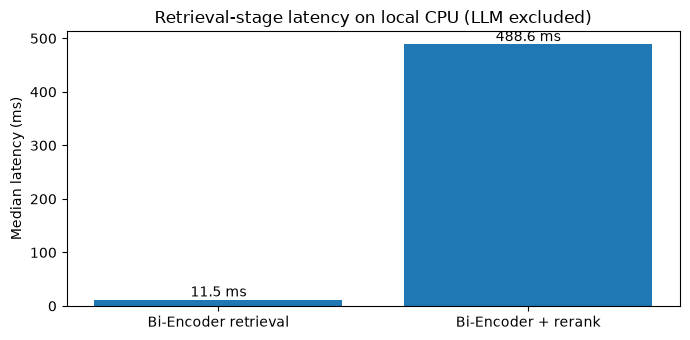

Keeping existing human annotations: c:\Users\dell\Downloads\M26\LMA\assignment1\results\manual_answer_evaluation.csv
Experiment outputs written to: c:\Users\dell\Downloads\M26\LMA\assignment1\results


In [29]:
import matplotlib.pyplot as plt

plot_data = [
    latency_df["baseline_retrieval_ms"].median(),
    latency_df["advanced_total_ms"].median(),
]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(["Bi-Encoder retrieval", "Bi-Encoder + rerank"], plot_data)
ax.set_ylabel("Median latency (ms)")
ax.set_title("Retrieval-stage latency on local CPU (LLM excluded)")
for idx, value in enumerate(plot_data):
    ax.text(idx, value, f"{value:.1f} ms", ha="center", va="bottom")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "latency_comparison.png", dpi=180)
plt.show()

# A fill-in evaluation table. Preserve any annotations you've already written.
eval_path = RESULTS_DIR / "manual_answer_evaluation.csv"
if not eval_path.exists():
    pd.DataFrame(columns=[
        "query_id", "baseline_factual_accuracy", "reranked_factual_accuracy",
        "baseline_omitted_clause", "reranked_fixed_clause", "hallucination_notes",
        "evidence_checked_against_pdf", "human_notes",
    ]).to_csv(eval_path, index=False)
    print("Created blank human evaluation sheet:", eval_path)
else:
    print("Keeping existing human annotations:", eval_path)

setup_info = {
    "pdf": PDF_PATH.name,
    "source_url": PDF_URL,
    "source_handbook": "https://handbook.fide.com/chapter/E012023",
    "pdf_page_count": len(pages),
    "chunks": len(chunks),
    "chunk_words": CHUNK_WORDS,
    "chunk_overlap_words": CHUNK_OVERLAP,
    "bi_encoder": BI_MODEL_ID,
    "cross_encoder": CROSS_MODEL_ID,
    "gemini_model": GEMINI_MODEL,
    "top_k": TOP_K,
    "context_k": FINAL_K,
    "device": "cpu",
    "python": platform.python_version(),
    "os": platform.platform(),
    "cpu_threads": torch.get_num_threads(),
    "repetitions": LATENCY_REPEATS,
}
(RESULTS_DIR / "experiment_config.json").write_text(json.dumps(setup_info, indent=2), encoding="utf-8")
print("Experiment outputs written to:", RESULTS_DIR)

## 14. Final validation 

In [31]:
expected_outputs = [
    "corpus_chunks.csv", "retrieval_results.json", "rank_changes_all.csv",
    "candidate_rank_shifts.csv", "latency_raw.csv", "latency_medians_per_query.csv",
    "latency_comparison.png", "experiment_config.json", "manual_answer_evaluation.csv",
]
for name in expected_outputs:
    print(("OK" if (RESULTS_DIR / name).exists() else "MISSING"), name)

paired_path = RESULTS_DIR / "paired_answers.json"
paired = json.loads(paired_path.read_text(encoding="utf-8")) if paired_path.exists() else {}
print("\nVerified rescue claims annotated:", len(VERIFIED_CASES))
print("Paired LLM answers generated:", len(paired))
if len(VERIFIED_CASES) < 2 or len(paired) < 2:
    print("INCOMPLETE: you still need two verified, answer-level failure analyses before submission.")
else:
    print("Retrieval and paired-answer exports ready.")



OK corpus_chunks.csv
OK retrieval_results.json
OK rank_changes_all.csv
OK candidate_rank_shifts.csv
OK latency_raw.csv
OK latency_medians_per_query.csv
OK latency_comparison.png
OK experiment_config.json
OK manual_answer_evaluation.csv

Verified rescue claims annotated: 3
Paired LLM answers generated: 3
Retrieval and paired-answer exports ready.
